In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"


In [2]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv('../data/Mall_Customers.csv')
df.shape

(200, 5)

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df = df.drop(['CustomerID'], axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Gender                  200 non-null    str  
 1   Age                     200 non-null    int64
 2   Annual Income (k$)      200 non-null    int64
 3   Spending Score (1-100)  200 non-null    int64
dtypes: int64(3), str(1)
memory usage: 7.4 KB


In [6]:
df.isna().sum()

Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['Gender_encoded'] = df['Gender'].map({'Male': 0, 'Female': 1})

In [9]:
df= df.drop(['Gender'], axis=1)
df.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded
0,19,15,39,0
1,21,15,81,0
2,20,16,6,1
3,23,16,77,1
4,31,17,40,1


In [10]:
df.describe()


,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded
count,200.000000,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000,0.560000
std,13.969007,26.264721,25.823522,0.497633
min,18.000000,15.000000,1.000000,0.000000
25%,28.750000,41.500000,34.750000,0.000000
50%,36.000000,61.500000,50.000000,1.000000
75%,49.000000,78.000000,73.000000,1.000000
max,70.000000,137.000000,99.000000,1.000000


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_scaled = scaler.fit_transform(df)

df_scaled  = pd.DataFrame(df_scaled, columns=df.columns)
df_scaled.describe()

,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded
count,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02
mean,-1.021405e-16,-2.131628e-16,-1.465494e-16,-7.549517e-17
std,1.002509e+00,1.002509e+00,1.002509e+00,1.002509e+00
min,-1.496335e+00,-1.738999e+00,-1.910021e+00,-1.128152e+00
25%,-7.248436e-01,-7.275093e-01,-5.997931e-01,-1.128152e+00
50%,-2.045351e-01,3.587926e-02,-7.764312e-03,8.864053e-01
75%,7.284319e-01,6.656748e-01,8.851316e-01,8.864053e-01
max,2.235532e+00,2.917671e+00,1.894492e+00,8.864053e-01


In [12]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA()
pca.fit(df_scaled.drop(['Gender_encoded'], axis=1))
print(np.cumsum(pca.explained_variance_ratio_))

[0.44266167 0.77574546 1.        ]


In [13]:
print(pca.components_)

[[ 0.70638235 -0.04802398 -0.70619946]
 [ 0.03014116  0.9988316  -0.03777499]
 [ 0.70718844  0.00539792  0.70700451]]


In [14]:
from sklearn.cluster import KMeans

inertias = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(df_scaled.drop(['Gender_encoded'], axis=1))
    inertias.append(model.inertia_)

print(inertias)


[599.9999999999999, 389.38618895643714, 295.21224615554877, 205.22514747675913, 168.2475801755683, 133.86842085478855, 117.01155455889815, 103.87329152383714, 93.0928911004172, 82.38515364526597]


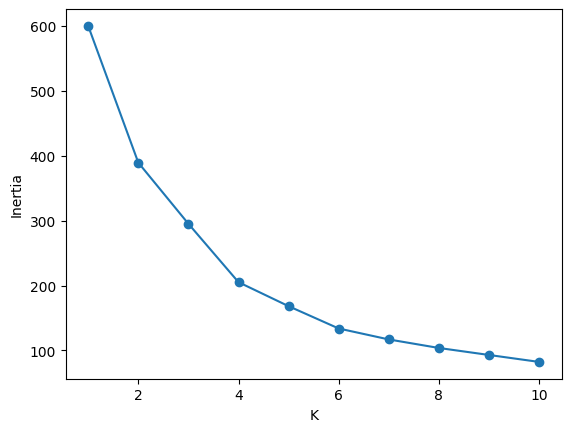

In [29]:
import matplotlib.pyplot as plt

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.savefig('images/elbow.png')
plt.show()

In [16]:
from sklearn.metrics import silhouette_score

X = df_scaled.drop(['Gender_encoded'], axis=1)

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    print(k, silhouette_score(X, labels))

2 0.33547192894004574
3 0.357793388710272
4 0.4039582785148566
5 0.41664341513732767
6 0.4284167762892593
7 0.417231894954916
8 0.4082067042807375


In [30]:
model = KMeans(n_clusters=4, n_init=10, random_state=42)
df['cluster'] = model.fit_predict(X)
print(df.groupby('cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean())

               Age  Annual Income (k$)  Spending Score (1-100)
cluster                                                       
0        53.984615           47.707692               39.969231
1        32.875000           86.100000               81.525000
2        25.438596           40.000000               60.298246
3        39.368421           86.500000               19.578947


In [31]:
model = KMeans(n_clusters=6, n_init=10, random_state=42)
df['cluster'] = model.fit_predict(X)
print(df.groupby('cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean())

               Age  Annual Income (k$)  Spending Score (1-100)
cluster                                                       
0        56.333333           54.266667               49.066667
1        26.794872           57.102564               48.128205
2        41.939394           88.939394               16.969697
3        32.692308           86.538462               82.128205
4        25.000000           25.260870               77.608696
5        45.523810           26.285714               19.380952


In [32]:
print(df['cluster'].value_counts().sort_index())

cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


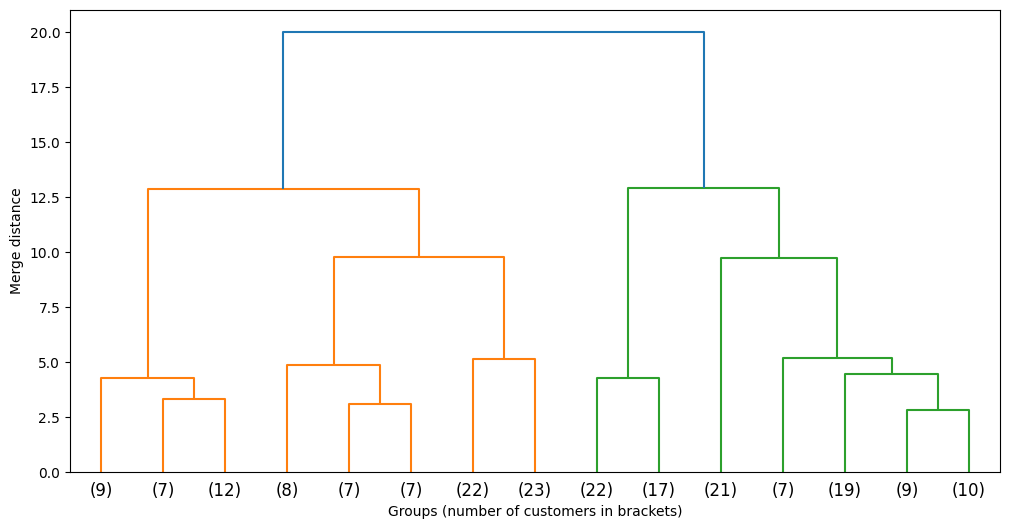

In [33]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=15)
plt.xlabel('Groups (number of customers in brackets)')
plt.ylabel('Merge distance')
plt.savefig('images/dendogram.png')
plt.show()

In [34]:
from scipy.cluster.hierarchy import fcluster
import pandas as pd

df['hier'] = fcluster(Z, t=6, criterion='maxclust')
print(pd.crosstab(df['cluster'], df['hier']))

hier      1   2   3   4   5   6
cluster                        
0         0   0  43   0   0   2
1         0   0   0   0   0  39
2        28   0   2   0   0   3
3         0   0   0  39   0   0
4         0   1   0   0  21   1
5         0  21   0   0   0   0


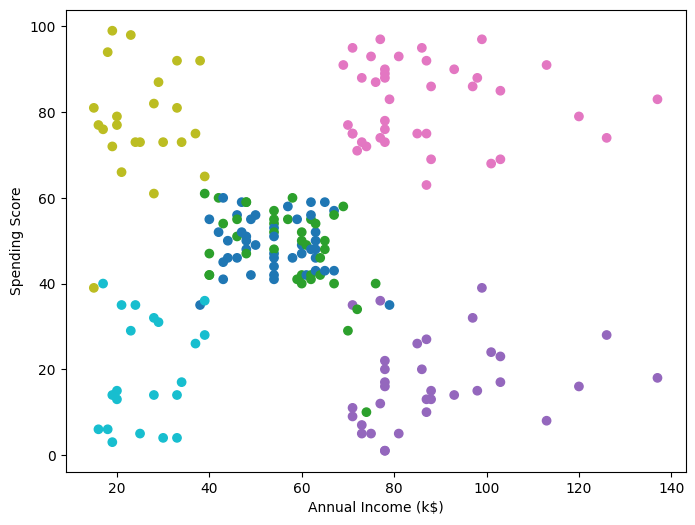

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'],
            c=df['cluster'], cmap='tab10')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.savefig('images/clusters_income_spending.png')
plt.show()

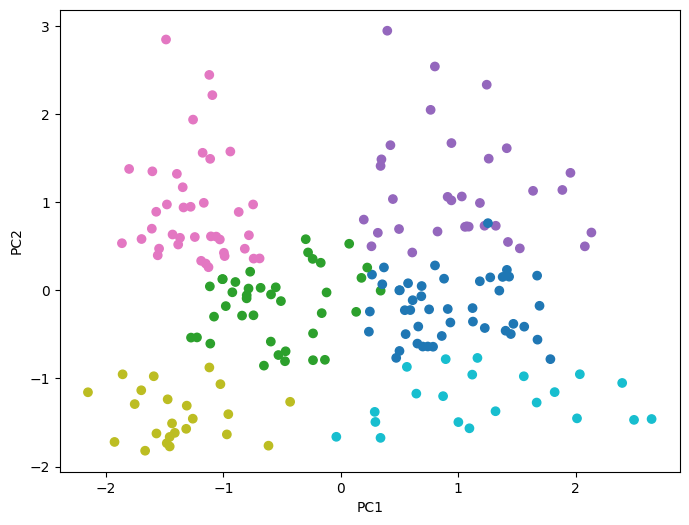

In [36]:
from sklearn.decomposition import PCA

pcs = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(pcs[:, 0], pcs[:, 1], c=df['cluster'], cmap='tab10')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()